In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier
from pdpbox import pdp

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, make_scorer, f1_score
from sklearn.utils.class_weight import compute_class_weight

In [2]:
# load final model data
df = pd.read_csv("model_data_final_v2.csv")

# multiclass mapping of target varible: InjurySeverity
df['InjurySeverity'].value_counts()
df['InjurySeverity'] = df['InjurySeverity'].map({5:0, 4:0, 3:1, 2:1, 1:2})
df['InjurySeverity'].value_counts()

# drop redundant cols
drop_cols = ['IncidentID', 
             'IncidentDateTime',
             'has_child',
             'first_harmful_fixed_object',
             'is_age_middle']
df.drop(drop_cols, axis = 1, inplace = True)

# rename column
df.rename(columns = {'first_hamrful_guardrail': 'first_harmful_guardrail'}, inplace = True)

In [3]:
# features and target variable
X = df.drop('InjurySeverity', axis = 1).copy()
y = df['InjurySeverity'].copy()

# train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify = y, test_size = 0.3, random_state = 42)

In [4]:
# compute class weights and map to sample weights
classes = np.unique(y_train)
class_weights = compute_class_weight(class_weight = 'balanced', classes = classes, y = y_train)
weight_dict = {i: class_weights[i] for i in range(len(class_weights))}
sample_weights = y_train.map(weight_dict)

In [5]:
# define model
lgb = LGBMClassifier(
    objective = 'multiclass',
    class_weight = None, # sample weights used
    num_class = 3,
    random_state = 42,
    n_jobs = -1,
    verbosity = -1
)

# hyperparameter grid
param_grid = {
    'max_depth': [7],
    'learning_rate': [0.2],
    'n_estimators': [100],
    'min_child_samples': [5],
    'subsample': [0.8],
    'colsample_bytree': [0.8],
    'reg_alpha': [0.1],
    'reg_lambda': [0.1]
}

# stratified 5-fold CV
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

# use macro F1 as scoring metric
scorer = make_scorer(f1_score, average = 'macro')

# grid search with sample weights
grid_search = GridSearchCV(
    estimator = lgb,
    param_grid = param_grid,
    cv = cv,
    scoring = scorer,
    verbose = 1,
    n_jobs = -1
)

grid_search.fit(X_train, y_train, sample_weight = sample_weights)
best_model = grid_search.best_estimator_
print(f"\nBest parameters: {grid_search.best_params_}\n")

# predict on test set
y_pred = best_model.predict(X_test)

Fitting 5 folds for each of 1 candidates, totalling 5 fits

Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.2, 'max_depth': 7, 'min_child_samples': 5, 'n_estimators': 100, 'reg_alpha': 0.1, 'reg_lambda': 0.1, 'subsample': 0.8}



In [6]:
# model evaluation
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, target_names = ['KA', 'BC', 'O'])

# confusion matrix
class_names = ['KA', 'BC', 'O']
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(
    cm,
    index = [f'Actual_{cls}' for cls in class_names],
    columns = [f'Predicted_{cls}' for cls in class_names]
)

print(f"LightGBM")
print(f"Accuracy: {round(accuracy, 4)}\n")
print(f"Classification Report: \n{report}\n")
print(f"Confusion Matrix: \n{cm_df}\n")

report_dict = classification_report(y_test, y_pred, target_names = ['KA', 'BC', 'O'], output_dict = True)

f1_scores = [
    report_dict['KA']['f1-score'],
    report_dict['BC']['f1-score'],
    report_dict['O']['f1-score']
]

harmonic_mean_f1 = len(f1_scores) / sum(1.0 / f for f in f1_scores if f > 0)
print(f"Harmonic Mean of F1-scores: {round(harmonic_mean_f1, 4)}")

LightGBM
Accuracy: 0.6374

Classification Report: 
              precision    recall  f1-score   support

          KA       0.33      0.26      0.30        34
          BC       0.39      0.36      0.37       148
           O       0.74      0.79      0.76       364

    accuracy                           0.64       546
   macro avg       0.49      0.47      0.48       546
weighted avg       0.62      0.64      0.63       546


Confusion Matrix: 
           Predicted_KA  Predicted_BC  Predicted_O
Actual_KA             9            13           12
Actual_BC             9            53           86
Actual_O              9            69          286

Harmonic Mean of F1-scores: 0.4073


In [11]:
# retrain full dataset using best hyperparameters
final_model = LGBMClassifier(
    objective = 'multiclass',
    num_class = 3,
    random_state = 42,
    n_jobs = -1,
    verbosity = -1,
    **grid_search.best_params_
)

final_model.fit(X, y)

LGBMClassifier(colsample_bytree=0.8, learning_rate=0.2, max_depth=7,
               min_child_samples=5, n_jobs=-1, num_class=3,
               objective='multiclass', random_state=42, reg_alpha=0.1,
               reg_lambda=0.1, subsample=0.8, verbosity=-1)

In [12]:
# function to plot PDP isolate
def plot_pdp_isolate(feature):
    pdp_iso = pdp.PDPIsolate(
        model = final_model,
        df = X,
        model_features = X.columns,
        feature = feature,
        feature_name = feature,
        n_classes = 3
    )
    fig, axes = pdp_iso.plot(plot_lines = True, plot_pts_dist = True)
    return fig

# function to plot PDP interaction
def plot_pdp_interact(features):
    pdp_interact = pdp.PDPInteract(
        model = final_model,
        df = X,
        model_features = X.columns,
        features = features,
        feature_names = features,
        n_classes = 3
    )
    fig, axes = pdp_interact.plot()
    return fig

obtain pred_func from the provided model.


  0%|          | 0/10 [00:00<?, ?it/s]

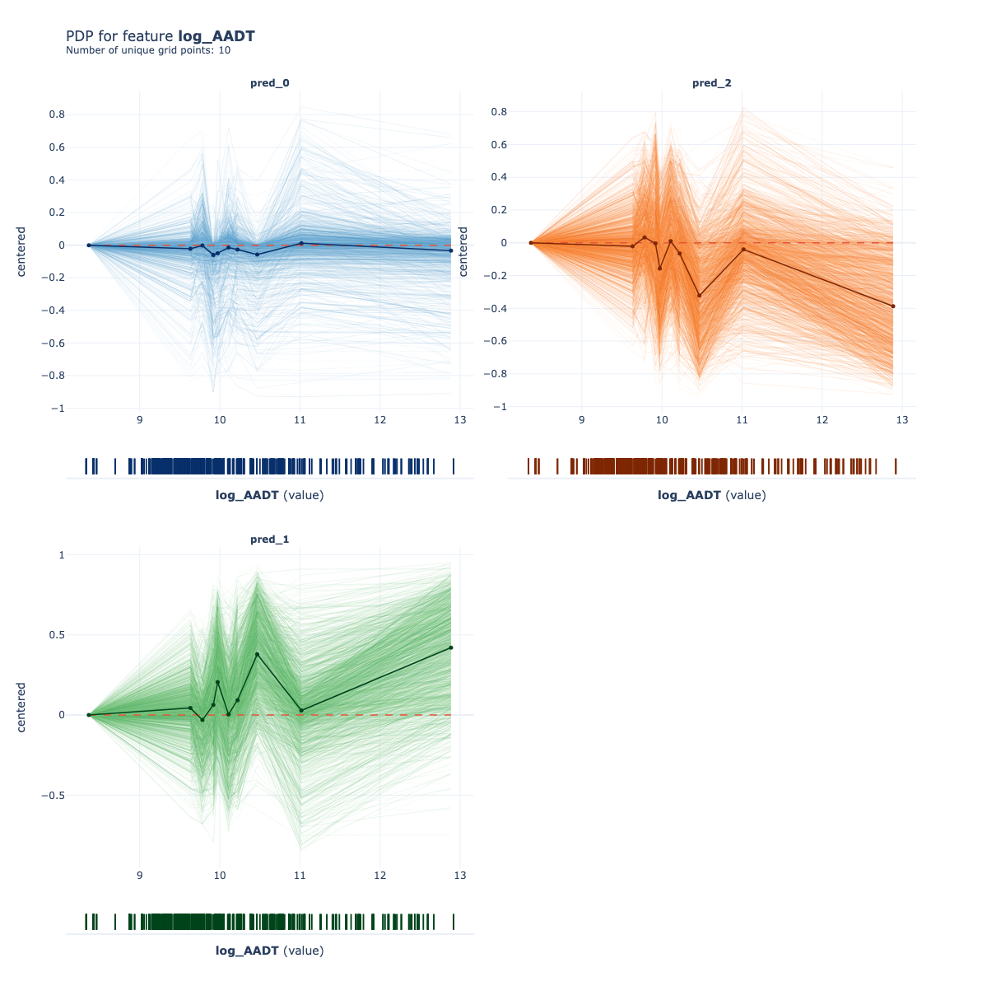

In [18]:
plot_pdp_isolate('log_AADT')

obtain pred_func from the provided model.


  0%|          | 0/2 [00:00<?, ?it/s]

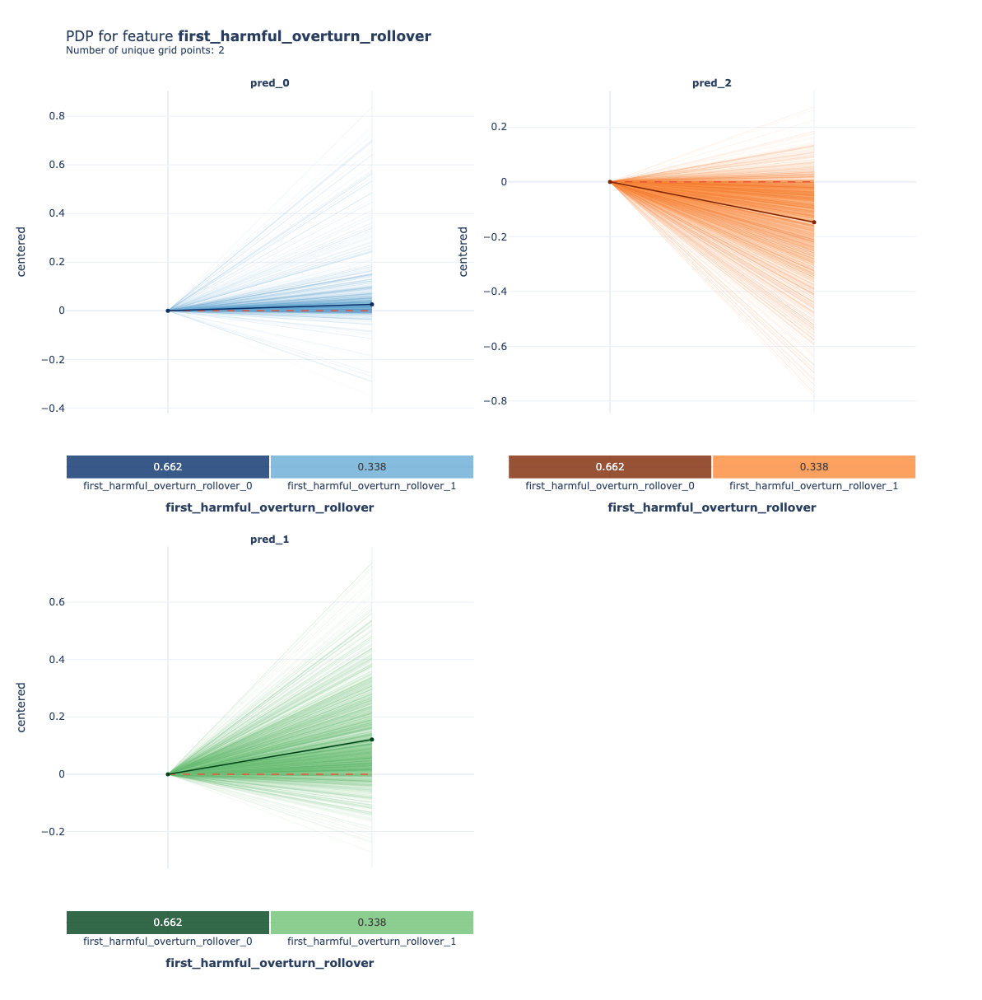

In [13]:
plot_pdp_isolate('first_harmful_overturn_rollover')

obtain pred_func from the provided model.


  0%|          | 0/2 [00:00<?, ?it/s]

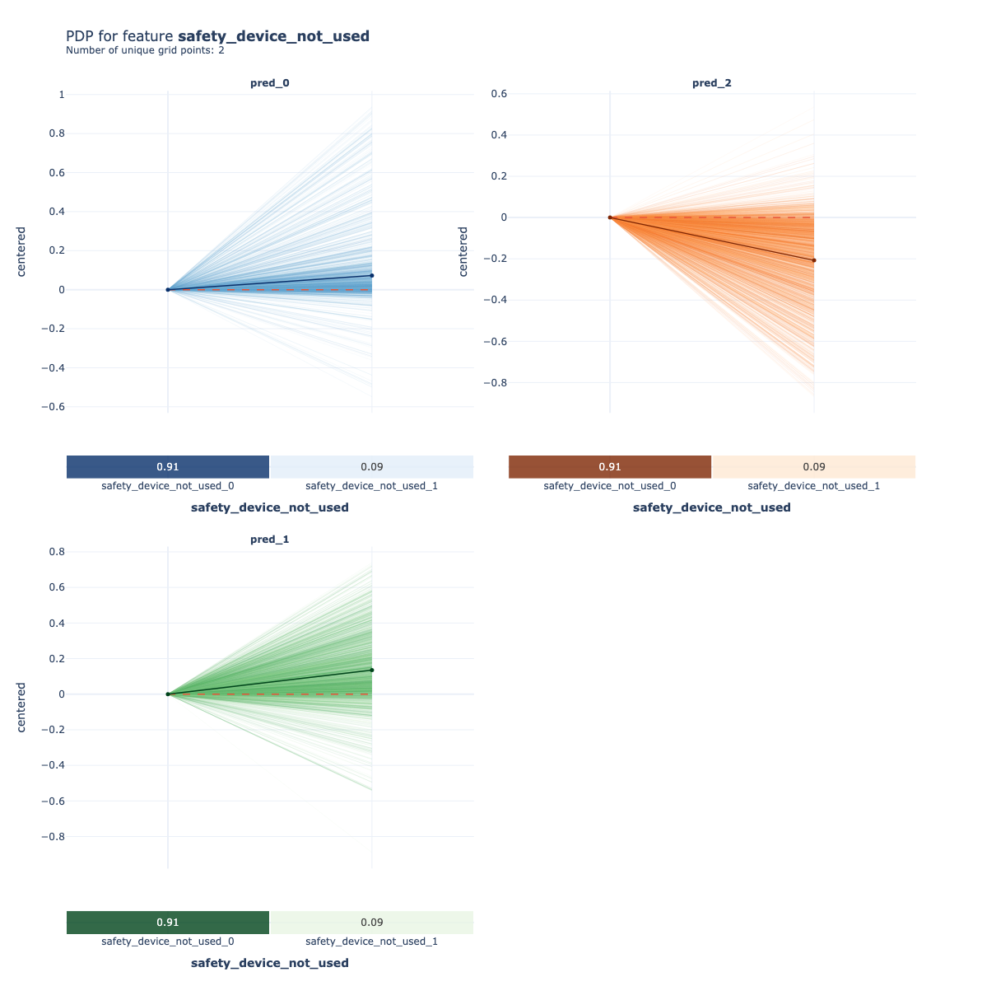

In [14]:
plot_pdp_isolate('safety_device_not_used')

In [ ]:
plot_pdp_interact(['first_harmful_overturn_rollover', 'log_AADT'])

In [ ]:
plot_pdp_interact(['is_distracted', 'log_AADT'])

In [15]:
binary_features = [f for f in list(df.columns) if f not in ['InjurySeverity', 'log_AADT']]
results = []

# loop through binary features
for feature in binary_features:
    pdp_iso = pdp.PDPIsolate(
        model = final_model,
        df = X,
        model_features = X.columns,
        feature = feature,
        feature_name = feature,
        n_classes = 3
    )

    # grid values
    grid_vals = list(pdp_iso.feature_info.grids)

    for class_index, pdp_result in enumerate(pdp_iso.results):
        try:
            idx_0 = grid_vals.index(0)
            idx_1 = grid_vals.index(1)

            # extract ICE values and center them
            ice_df = pdp_result.ice_lines
            ice_centered = ice_df.iloc[:, idx_1] - ice_df.iloc[:, idx_0]

            avg_effect = round(ice_centered.mean() * 100, 2)
            std_effect = round(ice_centered.std() * 100, 2)

        except ValueError:
            avg_effect = None
            std_effect = None

        results.append({
            'feature': feature,
            'class': class_index,
            'avg_pdp': avg_effect,
            'std_ice': std_effect
        })

obtain pred_func from the provided model.


  0%|          | 0/2 [00:00<?, ?it/s]

obtain pred_func from the provided model.


  0%|          | 0/2 [00:00<?, ?it/s]

obtain pred_func from the provided model.


...

  0%|          | 0/2 [00:00<?, ?it/s]

obtain pred_func from the provided model.


  0%|          | 0/2 [00:00<?, ?it/s]

obtain pred_func from the provided model.


  0%|          | 0/2 [00:00<?, ?it/s]

In [16]:
# final dataframe
df_ice = pd.DataFrame(results)

# pivot to wide format
df_ice_wide = df_ice.pivot(index = 'feature', columns = 'class')[['avg_pdp', 'std_ice']]
df_ice_wide.columns = [f'{stat}_{cls}' for stat, cls in df_ice_wide.columns]
df_ice_wide = df_ice_wide.reset_index()
df_ice_wide.rename(columns = lambda col: col.replace('_0', '_KA').replace('_1', '_BC').replace('_2', '_O'), inplace = True)

# save results
df_ice_wide.to_csv("results_PDP_ICE_binary.csv")
df_ice_wide

,feature,avg_pdp_KA,avg_pdp_BC,avg_pdp_O,std_ice_KA,std_ice_BC,std_ice_O
0,AZ_registered,1.14,-3.38,2.23,6.99,11.88,11.04
1,DUI_involved,4.71,9.92,-14.63,12.37,19.67,19.49
2,airbag_not_deployed,-2.02,-0.53,2.55,9.77,11.22,11.99
3,fell_asleep_fatigued,0.39,7.13,-7.53,5.04,12.48,13.37
4,first_harmful_guardrail,0.03,0.74,-0.77,3.75,9.23,9.59
5,first_harmful_overturn_rollover,2.63,12.09,-14.72,8.99,14.67,15.86
6,has_female,1.21,1.90,-3.12,6.42,9.01,10.54
7,is_AADT_trucks_below_25_percent,1.64,2.15,-3.79,7.37,10.91,10.93
8,is_PSL_below_65,-2.08,-7.10,9.18,7.86,15.94,16.78
9,is_age_old,-0.72,10.13,-9.41,4.40,18.32,17.83


In [17]:
pdp_iso = pdp.PDPIsolate(
    model = final_model,
    df = X,
    model_features = X.columns,
    feature = 'log_AADT',
    feature_name = 'log_AADT',
    n_classes = 3
)

# extract PDP
pdp_ka = pdp_iso.results[0].pdp
pdp_bc = pdp_iso.results[1].pdp
pdp_o = pdp_iso.results[2].pdp

# center using the first grid value (lowest log_AADT)
pdp_ka_centered = pdp_ka - pdp_ka[0]
pdp_bc_centered = pdp_bc - pdp_bc[0]
pdp_o_centered = pdp_o - pdp_o[0]

# extract ICE lines
ice_ka = pdp_iso.results[0].ice_lines
ice_bc = pdp_iso.results[1].ice_lines
ice_o = pdp_iso.results[2].ice_lines

# center each row using value at lowest log_AADT (first column)
ice_ka_centered = ice_ka.sub(ice_ka.iloc[:, 0], axis=0)
ice_bc_centered = ice_bc.sub(ice_bc.iloc[:, 0], axis=0)
ice_o_centered = ice_o.sub(ice_o.iloc[:, 0], axis=0)

# compute std across rows (heterogeneity)
std_ka = ice_ka_centered.std(axis = 0)
std_bc = ice_bc_centered.std(axis = 0)
std_o = ice_o_centered.std(axis = 0)

df_log_AADT = pd.DataFrame({
    'log_AADT': pdp_iso.feature_info.grids,
    'avg_pdp_KA': pdp_ka_centered,
    'avg_pdp_BC': pdp_bc_centered,
    'avg_pdp_O': pdp_o_centered,
    'std_pdp_KA': std_ka,
    'std_pdp_BC': std_bc,
    'std_pdp_O': std_o
})
df_log_AADT

obtain pred_func from the provided model.


  0%|          | 0/10 [00:00<?, ?it/s]

,log_AADT,avg_pdp_KA,avg_pdp_BC,avg_pdp_O,std_pdp_KA,std_pdp_BC,std_pdp_O
0,8.364741,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,9.633121,-0.021864,0.043389,-0.021525,0.110452,0.176610,0.181098
2,9.782675,-0.002178,-0.031042,0.033221,0.119194,0.185100,0.195778
3,9.919213,-0.059408,0.063023,-0.003615,0.136115,0.210127,0.233282
4,9.973340,-0.049330,0.206226,-0.156896,0.135280,0.227140,0.232804
5,10.109119,-0.014969,0.004504,0.010465,0.131861,0.226402,0.231665
6,10.221287,-0.027602,0.092915,-0.065313,0.124253,0.242930,0.241628
7,10.467260,-0.056982,0.379319,-0.322337,0.133046,0.257520,0.259715
8,11.018842,0.011921,0.028329,-0.040250,0.158420,0.261285,0.245790
9,12.886590,-0.033315,0.420257,-0.386941,0.143507,0.277719,0.269369


In [ ]:
feature = 'log_AADT'
pdp_iso = pdp.PDPIsolate(
    model = final_model,
    df = X,
    model_features = X.columns,
    feature = feature,
    feature_name = feature,
    n_classes = 3
)

fig, axes = pdp_iso.plot(
    plot_lines = True, 
    plot_pts_dist = True, 
    figsize = (10, 8), 
    ncols = 3, 
    engine = 'matplotlib', 
    dpi = 1200
)

# specify class titles
class_titles = ['(a) Class KA', '(b) Class BC', '(c) Class O']
for ax, title in zip(axes['line_axes'], class_titles):
    ax.set_title(title, fontweight = 'bold')

# remove y label in 2nd and 3rd plots
for ax in axes['line_axes'][1:]:
    ax.set_ylabel('')

# remove subtitle 'distribution of data points'
for ax in axes['dist_axes']:
    ax.set_title('')

# adjust plot spacing and save
# fig.subplots_adjust(left = 0.08, right = 0.98)
fig.savefig(f'output/pdp_ice_plots/pdp_{feature}.png', dpi = 1200)

obtain pred_func from the provided model.


  0%|          | 0/10 [00:00<?, ?it/s]

In [ ]:
feature = 'first_harmful_overturn_rollover'
pdp_iso = pdp.PDPIsolate(
    model = final_model,
    df = X,
    model_features = X.columns,
    feature = feature,
    feature_name = feature,
    n_classes = 3
)

fig, axes = pdp_iso.plot(
    plot_lines = True, 
    plot_pts_dist = True, 
    figsize = (10, 8), 
    ncols = 3, 
    engine = 'matplotlib', 
    dpi = 1200
)

# specify class titles
class_titles = ['(a) Class KA', '(b) Class BC', '(c) Class O']
for ax, title in zip(axes['line_axes'], class_titles):
    ax.set_title(title, fontweight = 'bold')

# remove y label in 2nd and 3rd plots
for ax in axes['line_axes'][1:]:
    ax.set_ylabel('')

# update line axes
xlim_a, xlim_b = -0.1, 1.1
for ax in axes['line_axes']:
    ax.set_xlim(xlim_a, xlim_b)

# updated distribution axes
for ax in axes['dist_axes']:
    # remove subtitle 'distribution of data points'
    ax.set_title('')

    # update x lim
    ax.set_xlim(xlim_a, xlim_b)

    # specify x tick labels
    xticks = ax.get_xticks()
    ax.set_xticks(xticks)
    ax.set_xticklabels(['No', 'Yes'])

    # move the x-axis labels up from colorbar (right below plot)
    ax.xaxis.set_label_position('top')
    ax.tick_params(axis = 'x', pad = -60)

    # remove label pad between xticks and xlabel
    ax.set_xlabel('first_harmful_overturn_rollover', labelpad = 15, fontweight = 'bold')

fig.savefig(f'output/pdp_ice_plots/pdp_{feature}.png', dpi = 1200)

obtain pred_func from the provided model.


  0%|          | 0/2 [00:00<?, ?it/s]

In [21]:
features = ['safety_device_not_used', 'first_harmful_overturn_rollover']
pdp_interact = pdp.PDPInteract(
    model = final_model,
    df = X,
    model_features = X.columns,
    features = features,
    feature_names = features,
    n_classes = 3
)
fig, axes = pdp_interact.plot(
    plot_type = 'grid',
    figsize = (10, 5),
    ncols = 3,
    engine = 'matplotlib',
    dpi = 1200
)

# remove colorbars from each axis (for grid plot)
for ax in axes['interact_axes']:
    # the last artist in the axes is colorbar - remove it
    if len(ax.images) > 0:
        ax.images[-1].colorbar.remove()
        
# class titles
class_titles = ['(a) Class KA', '(b) Class BC', '(c) Class O']

# update titles and axis labels
for i, (ax, title) in enumerate(zip(axes['interact_axes'], class_titles)):
    # set x title and label
    ax.set_title(title, fontweight = 'bold')
    ax.set_xlabel(features[0], fontweight = 'bold')

    # remove y label for 2nd and 3rd plots
    if i == 0:
        ax.set_ylabel(features[1], fontweight = 'bold')
    else:
        ax.set_ylabel('')

    # specify x tick labels
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['No', 'Yes'])

    # specify y tick labels
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['No', 'Yes'])

fig.savefig(f'output/pdp_ice_plots/pdp_interaction_safety_device_first_harmful.png', bbox_inches = 'tight', dpi = 1200)

obtain pred_func from the provided model.


  0%|          | 0/2 [00:00<?, ?it/s]

obtain pred_func from the provided model.


  0%|          | 0/2 [00:00<?, ?it/s]

obtain pred_func from the provided model.


  0%|          | 0/4 [00:00<?, ?it/s]

In [22]:
features = ['airbag_not_deployed', 'first_harmful_overturn_rollover']
pdp_interact = pdp.PDPInteract(
    model = final_model,
    df = X,
    model_features = X.columns,
    features = features,
    feature_names = features,
    n_classes = 3
)
fig, axes = pdp_interact.plot(
    plot_type = 'grid',
    figsize = (10, 5),
    ncols = 3,
    engine = 'matplotlib',
    dpi = 1200
)

# remove colorbars from each axis (for grid plot)
for ax in axes['interact_axes']:
    # the last artist in the axes is colorbar - remove it
    if len(ax.images) > 0:
        ax.images[-1].colorbar.remove()
        
# class titles
class_titles = ['(a) Class KA', '(b) Class BC', '(c) Class O']

# update titles and axis labels
for i, (ax, title) in enumerate(zip(axes['interact_axes'], class_titles)):
    # set x title and label
    ax.set_title(title, fontweight = 'bold')
    ax.set_xlabel(features[0], fontweight = 'bold')

    # remove y label for 2nd and 3rd plots
    if i == 0:
        ax.set_ylabel(features[1], fontweight = 'bold')
    else:
        ax.set_ylabel('')

    # specify x tick labels
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['No', 'Yes'])

    # specify y tick labels
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['No', 'Yes'])

fig.savefig(f'output/pdp_ice_plots/pdp_interaction_airbag_first_harmful.png', bbox_inches = 'tight', dpi = 1200)

obtain pred_func from the provided model.


  0%|          | 0/2 [00:00<?, ?it/s]

obtain pred_func from the provided model.


  0%|          | 0/2 [00:00<?, ?it/s]

obtain pred_func from the provided model.


  0%|          | 0/4 [00:00<?, ?it/s]

In [23]:
features = ['safety_device_not_used', 'is_distracted']
pdp_interact = pdp.PDPInteract(
    model = final_model,
    df = X,
    model_features = X.columns,
    features = features,
    feature_names = features,
    n_classes = 3
)
fig, axes = pdp_interact.plot(
    plot_type = 'grid',
    figsize = (10, 5),
    ncols = 3,
    engine = 'matplotlib',
    dpi = 1200
)

# remove colorbars from each axis (for grid plot)
for ax in axes['interact_axes']:
    # the last artist in the axes is colorbar - remove it
    if len(ax.images) > 0:
        ax.images[-1].colorbar.remove()
        
# class titles
class_titles = ['(a) Class KA', '(b) Class BC', '(c) Class O']

# update titles and axis labels
for i, (ax, title) in enumerate(zip(axes['interact_axes'], class_titles)):
    # set x title and label
    ax.set_title(title, fontweight = 'bold')
    ax.set_xlabel(features[0], fontweight = 'bold')

    # remove y label for 2nd and 3rd plots
    if i == 0:
        ax.set_ylabel(features[1], fontweight = 'bold')
    else:
        ax.set_ylabel('')

    # specify x tick labels
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['No', 'Yes'])

    # specify y tick labels
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['No', 'Yes'])

fig.savefig(f'output/pdp_ice_plots/pdp_interaction_safety_device_distracted.png', bbox_inches = 'tight', dpi = 1200)

obtain pred_func from the provided model.


  0%|          | 0/2 [00:00<?, ?it/s]

obtain pred_func from the provided model.


  0%|          | 0/2 [00:00<?, ?it/s]

obtain pred_func from the provided model.


  0%|          | 0/4 [00:00<?, ?it/s]